# WICOS Project - Model 4: Convolutional Neural Network
The assignment requires at least one deep neural network (Lecture 5). In this notebook we train a small convolutional neural network (CNN, Lecture 7) on the pre-processed spectrogram images (128 × 128 pixels). Instead of hand-crafted features or PCA, the CNN *learns* its own features with convolution kernels, like the edge-detection kernels of CodeLab 4.

The network has four blocks of convolution (3 × 3 kernels) → ReLU → max pooling (2 × 2), followed by dropout and a dense softmax layer for the four gestures. It is trained with mini-batch stochastic gradient descent on the cross-entropy loss. With only 960 samples the network is kept small to limit overfitting, which is further reduced with dropout and early stopping on the validation loss (Lecture 5).

The aim of the project is to recognise a gesture *regardless of the person who performs it*. The 40 samples per person and gesture are cut from one continuous recording, so samples of the same person are very similar. With a random split, the model sees the test person during training and the score is too optimistic.

All models are therefore validated with **leave-one-person-out (LOPO)** cross-validation: the model is trained on five persons and tested on the sixth, once for every person. Hyperparameters are chosen with a second LOPO loop *inside* the five training persons (nested cross-validation), so the test person is never used to choose the model.

Training a CNN is much slower than an SVM, so the inner loop uses **one** validation person instead of all five: for test person F, the network is trained on A-D and validated on E, and so on. The validation person is used for early stopping and to choose the hyperparameters. The chosen network is then tested once on the held-out person.

In [1]:
# Import packages needed for the lab
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # hide TensorFlow info messages
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

C:\Users\hawma\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.stats import gaussian_kde


In [2]:
SEED = 42
keras.utils.set_random_seed(SEED)               # seeds Python, NumPy and TensorFlow
tf.config.experimental.enable_op_determinism()  # same result on every run

# Folders for the report figures and the results
FIG_DIR = Path("../reports/figures")
RES_DIR = Path("../results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

# Training settings
EPOCHS = 100        # maximum number of epochs
BATCH_SIZE = 32     # mini-batch size
PATIENCE = 10       # early stopping: stop after 10 epochs without a lower validation loss

## Task 1 - Data Preparation
- Load the pre-processed images and add a channel axis: Keras expects images of shape (height, width, channels).

In [3]:
# Load the prepared dataset (created by src/prepare_data.py)
data = np.load("../data/processed/wicos_dataset.npz", allow_pickle=True)

X = data["X_img"][..., np.newaxis]          # (960, 128, 128, 1): Doppler x time x channel, values in [0, 1]
y = data["y"]                               # 0=wave, 1=pinch, 2=swipe, 3=click
persons = data["persons"]                   # person who performed the gesture (A-F)
gestures = list(data["gestures"])

print("Images X: " + str(X.shape))
print("Label vector y: " + str(y.shape))

Images X: (960, 128, 128, 1)
Label vector y: (960,)


The function `lopo_scores` computes the accuracy and macro-F1 score for every held-out person. Macro-F1 averages the F1 score of the four gestures, so every gesture counts equally. `print_scores` prints the mean ± standard deviation over the six persons.

In [4]:
def lopo_scores(y_true, y_pred, groups):
    # Accuracy and macro-F1 per held-out person
    rows = []
    for p in np.unique(groups):
        mask = groups == p
        rows.append({
            "person": p,
            "accuracy": accuracy_score(y_true[mask], y_pred[mask]),
            "f1_macro": f1_score(y_true[mask], y_pred[mask], average="macro"),
        })
    return pd.DataFrame(rows)


def print_scores(scores):
    # Mean and standard deviation over the six persons
    print("Accuracy: " + f"{scores.accuracy.mean():.3f} ± {scores.accuracy.std():.3f}")
    print("F1 score (macro): " + f"{scores.f1_macro.mean():.3f} ± {scores.f1_macro.std():.3f}")

## Task 2 - CNN architecture
- Develop the function `build_cnn` that creates and compiles the network for a given learning rate, dropout rate and number of filters in the first layer. The number of filters doubles in the second and third block.
- Print the summary of the network and its number of trainable parameters.

In [5]:
def build_cnn(learning_rate=0.03, dropout=0.5, n_filters=8):
    # Four blocks of convolution -> ReLU -> max pooling, then dropout and a softmax layer
    model = keras.Sequential([
        keras.Input(shape=(128, 128, 1)),
        layers.Conv2D(n_filters, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(2 * n_filters, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(4 * n_filters, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(4 * n_filters, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dropout(dropout),
        layers.Dense(4, activation="softmax"),
    ])
    # Mini-batch stochastic gradient descent on the cross-entropy loss
    model.compile(
        optimizer=keras.optimizers.SGD(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


build_cnn().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 8)    │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,332 (91.14 KB)

 Trainable params: 23,332 (91.14 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
def train_cnn(params, X_train, y_train, X_val, y_val):
    # Train one network with early stopping on the validation loss
    keras.utils.set_random_seed(SEED)
    model = build_cnn(**params)
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=0,
    )
    return model, history

## Task 3 - Baseline model and learning curves
- Train the network with the default settings (learning rate 0.03, dropout 0.5, 8 filters) on persons A-D, with person E as validation person.
- Plot the training and validation loss and accuracy per epoch and mark the epoch chosen by early stopping.
- Test the network on person F.

In [7]:
#Baseline: train on A-D, validate on E, test on F
train_mask = np.isin(persons, ["A", "B", "C", "D"])
val_mask = persons == "E"
test_mask = persons == "F"

baseline_params = {"learning_rate": 0.03, "dropout": 0.5, "n_filters": 8}
model, history = train_cnn(baseline_params, X[train_mask], y[train_mask], X[val_mask], y[val_mask])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1

y_pred_f = model.predict(X[test_mask], verbose=0).argmax(axis=1)
print(f"Early stopping: best epoch {best_epoch} of {len(history.history['loss'])}")
print("Accuracy on person F: " + str(round(accuracy_score(y[test_mask], y_pred_f), 3)))
print("F1 score (macro) on person F: " + str(round(f1_score(y[test_mask], y_pred_f, average="macro"), 3)))

Early stopping: best epoch 7 of 17
Accuracy on person F: 0.781
F1 score (macro) on person F: 0.77


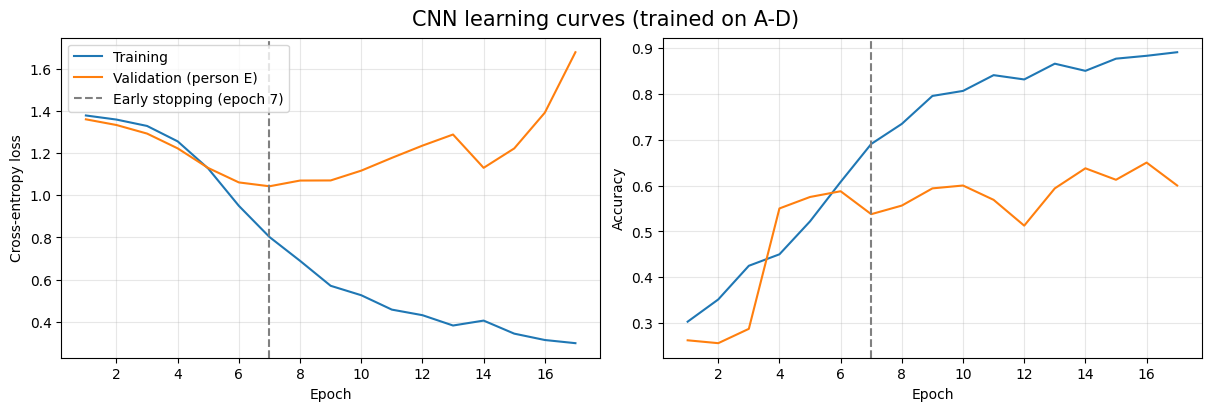

In [8]:
#Learning curves
epochs = np.arange(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(epochs, history.history["loss"], label="Training")
axes[0].plot(epochs, history.history["val_loss"], label="Validation (person E)")
axes[0].set_ylabel("Cross-entropy loss")
axes[1].plot(epochs, history.history["accuracy"], label="Training")
axes[1].plot(epochs, history.history["val_accuracy"], label="Validation (person E)")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--", label=f"Early stopping (epoch {best_epoch})")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle("CNN learning curves (trained on A-D)", fontsize=15)
fig.savefig(FIG_DIR / "cnn_learning_curves.pdf", bbox_inches="tight")
plt.show()

## Task 4 - Nested leave-one-person-out evaluation with hyperparameter tuning
- For every test person: train every combination of learning rate, dropout and number of filters on four persons, with early stopping on the fifth (validation) person.
- Choose the combination with the highest validation macro-F1 and test that network once on the held-out person.
- Test the network with the baseline settings (Task 3) of the same fold as well, so the baseline and the tuned model can be compared per person.

> **NOTE**: this cell trains 72 networks and takes about 10 minutes on a laptop CPU.

In [9]:
#Hyperparameter grid
param_grid = [
    {"learning_rate": lr, "dropout": dr, "n_filters": nf}
    for lr in [0.01, 0.03, 0.1]
    for dr in [0.25, 0.5]
    for nf in [8, 16]
]

#Nested leave-one-person-out
order = sorted(np.unique(persons))
y_pred_base = np.zeros_like(y)
y_pred_nested = np.zeros_like(y)
tuning_rows, best_rows = [], []

for i, test_person in enumerate(order):
    val_person = order[(i + 1) % len(order)]
    test_mask = persons == test_person
    val_mask = persons == val_person
    fit_mask = ~test_mask & ~val_mask

    # Inner loop: every setting is trained on four persons and validated on the fifth
    models = []
    for params in param_grid:
        model, history = train_cnn(params, X[fit_mask], y[fit_mask], X[val_mask], y[val_mask])
        y_val_pred = model.predict(X[val_mask], verbose=0).argmax(axis=1)
        models.append(model)
        tuning_rows.append({
            "test_person": test_person,
            **params,
            "val_f1": f1_score(y[val_mask], y_val_pred, average="macro"),
            "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
        })

    # Choose the setting with the highest validation score (the test person is not used)
    fold = pd.DataFrame(tuning_rows[-len(param_grid):])
    best = int(fold.val_f1.idxmax())
    base = param_grid.index(baseline_params)

    # Outer loop: test the chosen network once on the held-out person
    y_pred_nested[test_mask] = models[best].predict(X[test_mask], verbose=0).argmax(axis=1)
    y_pred_base[test_mask] = models[base].predict(X[test_mask], verbose=0).argmax(axis=1)

    best_rows.append({"person": test_person, **param_grid[best], "epochs": int(fold.best_epoch[best])})
    print(f"Person {test_person} held out (validation {val_person}) -> best parameters: {best_rows[-1]}")

tuning = pd.DataFrame(tuning_rows)
scores_base = lopo_scores(y, y_pred_base, persons)
scores_nested = lopo_scores(y, y_pred_nested, persons).merge(pd.DataFrame(best_rows), on="person")
scores_nested

Person A held out (validation B) -> best parameters: {'person': 'A', 'learning_rate': 0.1, 'dropout': 0.5, 'n_filters': 16, 'epochs': 3}
Person B held out (validation C) -> best parameters: {'person': 'B', 'learning_rate': 0.03, 'dropout': 0.5, 'n_filters': 8, 'epochs': 24}
Person C held out (validation D) -> best parameters: {'person': 'C', 'learning_rate': 0.03, 'dropout': 0.5, 'n_filters': 16, 'epochs': 8}
Person D held out (validation E) -> best parameters: {'person': 'D', 'learning_rate': 0.01, 'dropout': 0.25, 'n_filters': 8, 'epochs': 21}
Person E held out (validation F) -> best parameters: {'person': 'E', 'learning_rate': 0.1, 'dropout': 0.5, 'n_filters': 8, 'epochs': 8}
Person F held out (validation A) -> best parameters: {'person': 'F', 'learning_rate': 0.1, 'dropout': 0.5, 'n_filters': 16, 'epochs': 3}


,person,accuracy,f1_macro,learning_rate,dropout,n_filters,epochs
0,A,0.48125,0.432546,0.10,0.50,16,3
1,B,0.46250,0.318566,0.03,0.50,8,24
2,C,0.66875,0.662938,0.03,0.50,16,8
3,D,0.62500,0.587775,0.01,0.25,8,21
4,E,0.58125,0.575144,0.10,0.50,8,8
5,F,0.66250,0.626399,0.10,0.50,16,3


In [10]:
#Performance metrics
print("Baseline:")
print_scores(scores_base)
print("Tuned (nested LOPO):")
print_scores(scores_nested)

Baseline:
Accuracy: 0.556 ± 0.189
F1 score (macro): 0.492 ± 0.247
Tuned (nested LOPO):
Accuracy: 0.580 ± 0.090
F1 score (macro): 0.534 ± 0.131


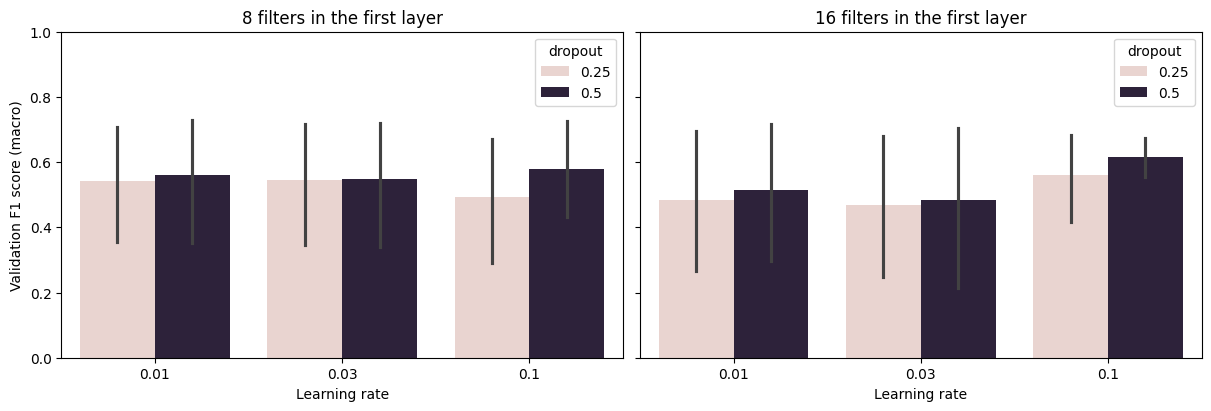

In [11]:
#Validation score per hyperparameter setting (mean over the six outer folds)
t = tuning

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
for ax, nf in zip(axes, [8, 16]):
    sn.barplot(data=t[t.n_filters == nf], x="learning_rate", y="val_f1", hue="dropout", ax=ax)
    ax.set_title(f"{nf} filters in the first layer")
    ax.set_xlabel("Learning rate")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Validation F1 score (macro)")
fig.savefig(FIG_DIR / "cnn_tuning.pdf", bbox_inches="tight")
plt.show()

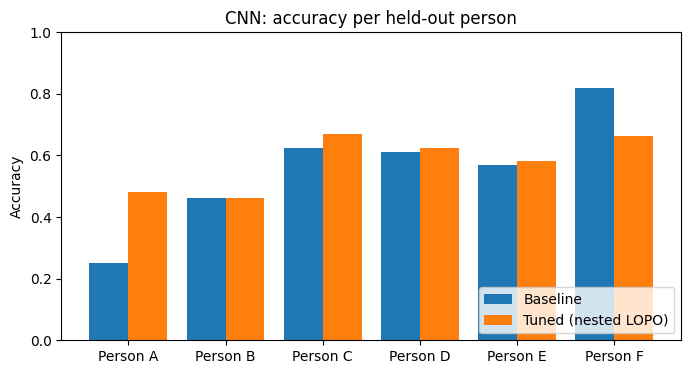

In [12]:
#Accuracy per held-out person: baseline vs tuned model
x = np.arange(len(scores_nested))

plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, scores_base.accuracy, width=0.4, label="Baseline")
plt.bar(x + 0.2, scores_nested.accuracy, width=0.4, label="Tuned (nested LOPO)")
plt.xticks(x, ["Person " + p for p in scores_nested.person])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("CNN: accuracy per held-out person")
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "cnn_per_person.pdf", bbox_inches="tight")
plt.show()

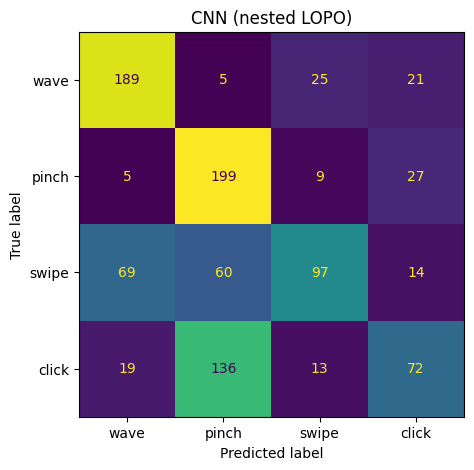

In [13]:
#Confusion matrix of the tuned model, summed over the six held-out persons
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y, y_pred_nested, display_labels=gestures, ax=ax, colorbar=False)
ax.set_title("CNN (nested LOPO)")
fig.savefig(FIG_DIR / "cnn_confusion_matrix.pdf", bbox_inches="tight")
plt.show()

## Task 5 - Comparison with a random split
The data exploration notebook (`wicos.ipynb`) uses a random, stratified 80/20 split. To show why we validate per person, the CNN is also trained and tested on that split.

- Use the setting with the highest mean validation score in Task 4.
- Train on the random training set, with random fold 0 as validation set for early stopping, and test on the random 20% test set.

In [14]:
#Random split: train on the random training set, test on the random 20% test set
idx_train, idx_test, cv_fold = data["idx_train"], data["idx_test"], data["cv_fold"]
fit_idx = idx_train[cv_fold[idx_train] != 0]
val_idx = idx_train[cv_fold[idx_train] == 0]

mean_val = t.groupby(["learning_rate", "dropout", "n_filters"]).val_f1.mean()
lr, dr, nf = mean_val.idxmax()
params_rs = {"learning_rate": float(lr), "dropout": float(dr), "n_filters": int(nf)}

model, history = train_cnn(params_rs, X[fit_idx], y[fit_idx], X[val_idx], y[val_idx])
y_pred_rs = model.predict(X[idx_test], verbose=0).argmax(axis=1)

accuracy_rs = accuracy_score(y[idx_test], y_pred_rs)
f1_rs = f1_score(y[idx_test], y_pred_rs, average="macro")
print("Parameters: " + str(params_rs))
print("Accuracy: " + str(round(accuracy_rs, 3)))
print("F1 score (macro): " + str(round(f1_rs, 3)))

Parameters: {'learning_rate': 0.1, 'dropout': 0.5, 'n_filters': 16}
Accuracy: 0.932
F1 score (macro): 0.932


In [15]:
#Random split vs leave-one-person-out
comparison = pd.DataFrame({
    "Accuracy": [accuracy_rs, scores_nested.accuracy.mean()],
    "F1 score (macro)": [f1_rs, scores_nested.f1_macro.mean()],
}, index=["Random 80/20 split", "Leave-one-person-out (mean)"])
comparison.round(3)

,Accuracy,F1 score (macro)
Random 80/20 split,0.932,0.932
Leave-one-person-out (mean),0.580,0.534


## Task 6 - Save the results
The per-person scores and a one-line summary are saved in `results/`, so all models can be compared in one table.

In [16]:
#Save the results
scores_nested.to_csv(RES_DIR / "cnn_lopo.csv", index=False)

summary = pd.DataFrame([{
    "model": "CNN (images)",
    "lopo_accuracy_mean": scores_nested.accuracy.mean(),
    "lopo_accuracy_std": scores_nested.accuracy.std(),
    "lopo_f1_mean": scores_nested.f1_macro.mean(),
    "lopo_f1_std": scores_nested.f1_macro.std(),
    "random_split_accuracy": accuracy_rs,
    "random_split_f1": f1_rs,
}])
summary.to_csv(RES_DIR / "cnn_summary.csv", index=False)
summary.round(3)

,model,lopo_accuracy_mean,lopo_accuracy_std,lopo_f1_mean,lopo_f1_std,random_split_accuracy,random_split_f1
0,CNN (images),0.58,0.09,0.534,0.131,0.932,0.932
